In [26]:
from pathlib import Path

import pandas as pd
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
import matplotlib.pyplot as plt

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [27]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

class_names = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

In [28]:
train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))

print(train_df.head())

Train: 4263
Validation: 512
   split       class                                              image  \
0  train      Glioma     ../data/raw/train/Glioma/images/Tr-gl_1184.jpg   
1  train  Meningioma  ../data/raw/train/Meningioma/images/Tr-me_0190...   
2  train   Pituitary     ../data/raw/train/Pituitary/images/p (669).jpg   
3  train  Meningioma  ../data/raw/train/Meningioma/images/Tr-me_0501...   
4  train   Pituitary  ../data/raw/train/Pituitary/images/Tr-pi_0777.jpg   

                                          annotation  label  
0     ../data/raw/train/Glioma/labels/Tr-gl_1184.txt      0  
1  ../data/raw/train/Meningioma/labels/Tr-me_0190...      1  
2     ../data/raw/train/Pituitary/labels/p (669).txt      3  
3  ../data/raw/train/Meningioma/labels/Tr-me_0501...      1  
4  ../data/raw/train/Pituitary/labels/Tr-pi_0777.txt      3  


In [52]:
# Fix training image paths
train_df["image"] = train_df["image"].str.replace(
    "/raw/train/",
    "/raw/Train/",
    regex=False
)

# Check the result
print(train_df["image"].iloc[0])
print("Image exists:", Path(train_df["image"].iloc[0]).exists())

../data/raw/Train/Glioma/images/Tr-gl_1184.jpg
Image exists: True


In [53]:
def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)

    image.set_shape((224, 224, 3))

    return image, label

In [54]:
def create_dataset(table, shuffle=False):

    paths = table["image"].tolist()
    labels = table["label"].tolist()

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)

    ds = ds.map(load_image)

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

In [55]:
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)

print("Datasets ready!")

Datasets ready!


In [56]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomZoom(0.05),
    tf.keras.layers.RandomContrast(0.1)
])

In [57]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

In [58]:
resnet_base = tf.keras.applications.ResNet50V2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

resnet_base.trainable = False

In [59]:
## MobileNetV2

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.layers.Rescaling(
    1./127.5,
    offset=-1
)(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    4,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

In [60]:
## ResNet50V2

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.layers.Rescaling(
    1./127.5,
    offset=-1
)(x)

x = resnet_base(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    4,
    activation="softmax"
)(x)

resnet_model = tf.keras.Model(inputs, outputs)

In [61]:
## MobileNetV2

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [62]:
## ResNet50V2

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_6 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,572,996 (89.92 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [63]:
## MobileNetV2

Path("../models").mkdir(
    parents=True,
    exist_ok=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "../models/best_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [64]:
## ResNet50V2

resnet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "../models/best_resnet50v2.keras",
    monitor="val_loss",
    save_best_only=True
)

resnet_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [69]:
## MobileNetV2

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        checkpoint,
        early_stopping
    ]
)

Epoch 1/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - accuracy: 0.8956 - loss: 0.2741 - val_accuracy: 0.8047 - val_loss: 0.5062
Epoch 2/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.8961 - loss: 0.2738 - val_accuracy: 0.8535 - val_loss: 0.3769
Epoch 3/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.8951 - loss: 0.2827 - val_accuracy: 0.8281 - val_loss: 0.4791


In [71]:
## ResNet50V2

history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        resnet_checkpoint,
        resnet_early_stopping
    ]
)

Epoch 1/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 23s 124ms/step - accuracy: 0.7047 - loss: 0.7630 - val_accuracy: 0.8066 - val_loss: 0.5303
Epoch 2/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step - accuracy: 0.8327 - loss: 0.4504 - val_accuracy: 0.8516 - val_loss: 0.4057
Epoch 3/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.8515 - loss: 0.4028 - val_accuracy: 0.8672 - val_loss: 0.3728
Epoch 4/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.8715 - loss: 0.3449 - val_accuracy: 0.8750 - val_loss: 0.3594
Epoch 5/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 16s 118ms/step - accuracy: 0.8754 - loss: 0.3262 - val_accuracy: 0.8691 - val_loss: 0.3480
Epoch 6/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step - accuracy: 0.8752 - loss: 0.3199 - val_accuracy: 0.8691 - val_loss: 0.3516
Epoch 7/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 16s 121ms/step - accuracy: 0.8890 - loss: 0.2960 - val_accuracy: 0.8887 - val_loss: 0.3105
Epoch 8/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 16s 121ms/step - accuracy: 0.8897 - loss: 0

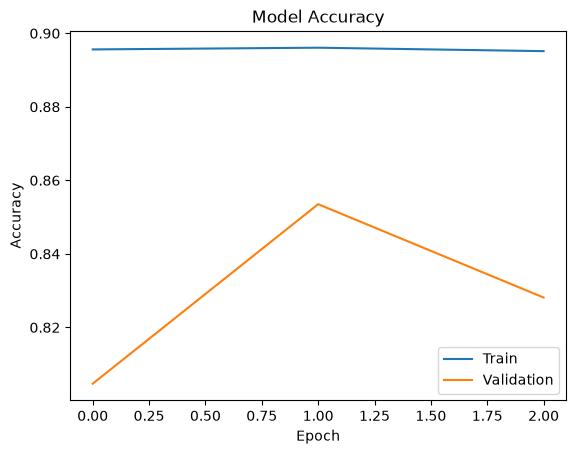

In [72]:
## MobileNetV2

plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()